# 04 - Model Training & Hyperparameter Tuning
**Goal:** find the best model fairly and cheaply.

Flow: baseline many models -> tune the promising ones -> inspect tuning -> check over/under-fitting -> try an ensemble -> save.

> Everything uses **train data only** with the same 5 folds. The test set is used once, in notebook 05.

In [1]:
from pathlib import Path
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV, validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              HistGradientBoostingClassifier, AdaBoostClassifier, VotingClassifier)
from sklearn.metrics import f1_score

sns.set_theme(style="whitegrid")
IN = Path("..") / "Artifacts" / "notebooks"
TARGET = "Result"
train = pd.read_csv(IN / "train_fe.csv")
X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("train:", X_train.shape, "| phishing share:", round(y_train.mean(), 3))

train: (8844, 30) | phishing share: 0.443


## 1. Baseline: many models, default settings
We score 5 metrics so we see more than accuracy. Linear/distance models get one-hot encoding because `-1/0/1` are categories, not magnitudes.

In [2]:
def onehot(model): return make_pipeline(OneHotEncoder(handle_unknown="ignore"), model)

models = {
    "LogisticRegression": onehot(LogisticRegression(max_iter=1000)),
    "KNN": onehot(KNeighborsClassifier()),
    "SVC (rbf)": onehot(SVC()),
    "MLP": onehot(MLPClassifier(max_iter=300, random_state=42)),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
    "RandomForest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "ExtraTrees": ExtraTreesClassifier(random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingClassifier(random_state=42),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
}
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
rows = []
for name, model in models.items():
    r = cross_validate(model, X_train, y_train, cv=CV, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, **{m: r[f"test_{m}"].mean() for m in scoring},
                 "f1_std": r["test_f1"].std(), "fit_sec": r["fit_time"].mean()})
baseline = pd.DataFrame(rows).set_index("model").sort_values("f1", ascending=False)
baseline.round(4)

/home/surya/ml-proj/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


,accuracy,precision,recall,f1,roc_auc,f1_std,fit_sec
model,,,,,,,
ExtraTrees,0.9722,0.9772,0.9597,0.9683,0.9909,0.0027,0.2914
MLP,0.9705,0.9724,0.9607,0.9665,0.9960,0.0033,7.4206
RandomForest,0.9692,0.9733,0.9569,0.9650,0.9945,0.0013,0.3010
HistGradientBoosting,0.9655,0.9641,0.9579,0.9610,0.9955,0.0031,0.2805
DecisionTree,0.9621,0.9662,0.9477,0.9568,0.9704,0.0047,0.0101
SVC (rbf),0.9547,0.9586,0.9382,0.9483,0.9909,0.0028,1.5565
KNN,0.9526,0.9581,0.9339,0.9458,0.9882,0.0029,0.0452
GradientBoosting,0.9472,0.9493,0.9306,0.9398,0.9895,0.0027,0.4985
LogisticRegression,0.9387,0.9384,0.9222,0.9302,0.9862,0.0043,0.1051


> **Reading the output:** Tree ensembles lead: ExtraTrees F1 0.968, MLP 0.967, RandomForest 0.965, with fold std of only about 0.003, so top ranks are close. LogisticRegression (0.930) and AdaBoost (0.920) trail clearly. Most models fit in under a second, only the MLP is slow (8 s).

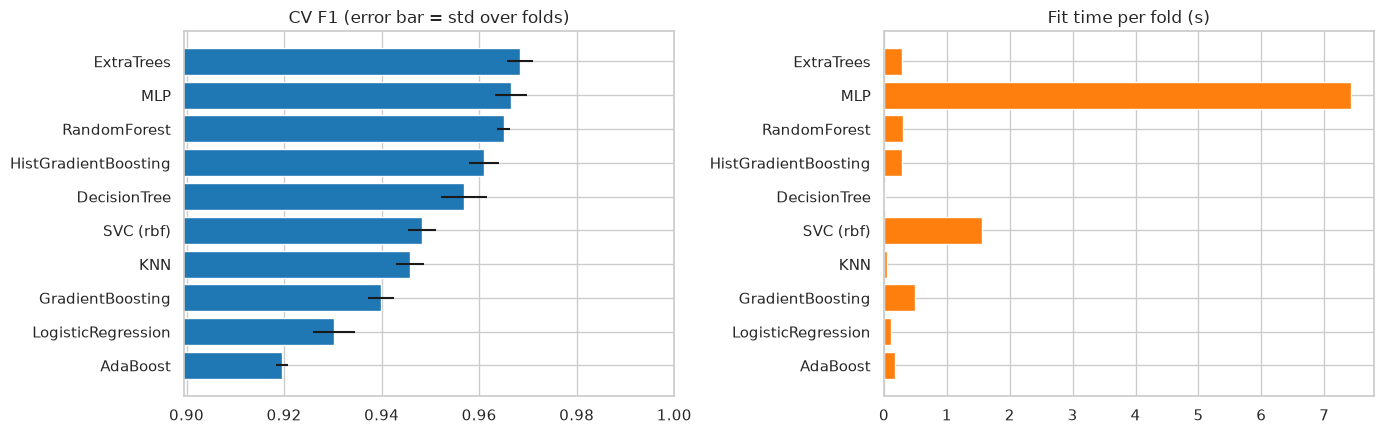

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
b = baseline.sort_values("f1")
ax[0].barh(b.index, b["f1"], xerr=b["f1_std"], color="tab:blue"); ax[0].set_xlim(b["f1"].min() - 0.02, 1)
ax[0].set_title("CV F1 (error bar = std over folds)")
ax[1].barh(b.index, b["fit_sec"], color="tab:orange"); ax[1].set_title("Fit time per fold (s)")
plt.tight_layout(); plt.show()

> **Reading the output:** Error bars for the top 4 models overlap, so their differences are small. The right chart shows cost: trees and boosting fit in under a second per fold while MLP and SVC are much slower. Fast and accurate models are the best tuning targets.

## 2. Hyperparameter tuning
`RandomizedSearchCV` samples random settings, so it is far cheaper than a full grid. We tune the top model families.

In [4]:
spaces = {
    "RandomForest": (RandomForestClassifier(random_state=42, n_jobs=-1), {
        "n_estimators": [100, 200, 400], "max_depth": [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", "log2", 0.5]}),
    "ExtraTrees": (ExtraTreesClassifier(random_state=42, n_jobs=-1), {
        "n_estimators": [100, 200, 400], "max_depth": [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10], "min_samples_leaf": [1, 2, 4], "max_features": ["sqrt", "log2", 0.5]}),
    "GradientBoosting": (GradientBoostingClassifier(random_state=42), {
        "n_estimators": [100, 200, 300], "learning_rate": [0.03, 0.1, 0.2],
        "max_depth": [2, 3, 5], "subsample": [0.7, 0.85, 1.0]}),
    "HistGradientBoosting": (HistGradientBoostingClassifier(random_state=42), {
        "learning_rate": [0.03, 0.05, 0.1, 0.2], "max_iter": [100, 200, 400],
        "max_leaf_nodes": [15, 31, 63], "l2_regularization": [0.0, 0.1, 1.0], "min_samples_leaf": [10, 20, 40]}),
    "LogisticRegression": (onehot(LogisticRegression(max_iter=2000)), {
        "logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
}

tuned, rows = {}, []
for name, (est, grid) in spaces.items():
    t = time.time()
    rs = RandomizedSearchCV(est, grid, n_iter=12, cv=CV, scoring="f1", random_state=42, n_jobs=-1).fit(X_train, y_train)
    tuned[name] = rs
    rows.append({"model": name, "default_f1": baseline.loc[name, "f1"], "tuned_f1": rs.best_score_,
                 "gain": rs.best_score_ - baseline.loc[name, "f1"], "search_sec": time.time() - t})
tuning = pd.DataFrame(rows).set_index("model").sort_values("tuned_f1", ascending=False)
tuning.round(4)

/home/surya/ml-proj/.venv/lib/python3.13/site-packages/sklearn/model_selection/_search.py:327: UserWarning: The total space of parameters 5 is smaller than n_iter=12. Running 5 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


,default_f1,tuned_f1,gain,search_sec
model,,,,
HistGradientBoosting,0.9610,0.9687,0.0077,5.5251
ExtraTrees,0.9683,0.9672,-0.0011,9.4862
RandomForest,0.9650,0.9655,0.0005,8.0276
GradientBoosting,0.9398,0.9653,0.0255,8.0953
LogisticRegression,0.9302,0.9303,0.0001,0.3316


> **Reading the output:** Tuning helped most for GradientBoosting (+0.026 F1) and HistGradientBoosting (+0.008). RF barely changed and ExtraTrees slightly dropped (-0.001, within noise), because their defaults were already good. HistGradientBoosting now leads with CV F1 0.9687.

In [5]:
for name, rs in tuned.items():
    print(f"{name:<22}", rs.best_params_)

RandomForest           {'n_estimators': 400, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}
ExtraTrees             {'n_estimators': 400, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}
GradientBoosting       {'subsample': 0.85, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1}
HistGradientBoosting   {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 100, 'learning_rate': 0.2, 'l2_regularization': 0.1}
LogisticRegression     {'logisticregression__C': 100}


> **Reading the output:** The winner uses 63 leaf nodes, learning rate 0.2 and L2 regularisation 0.1. Both forests chose `max_depth` 20 with `sqrt` features. LogisticRegression picked the largest C (100), meaning it wanted less regularisation but still stayed linear and weak.

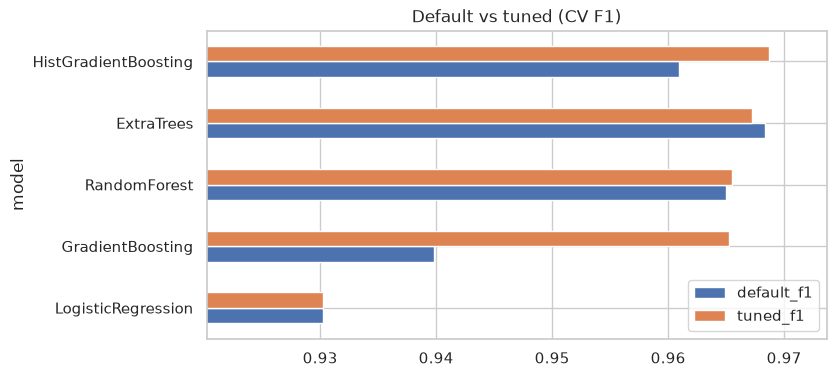

In [6]:
tuning[["default_f1", "tuned_f1"]].sort_values("tuned_f1").plot(kind="barh", figsize=(8, 4))
plt.xlim(tuning["default_f1"].min() - 0.01, tuning["tuned_f1"].max() + 0.005)
plt.title("Default vs tuned (CV F1)"); plt.show()

> **Reading the output:** The tuned bar exceeds the default bar clearly only for the two boosting models. Where bars are equal, more tuning is unlikely to help. Gains beyond this need better features or data, not more search.

## 3. How much did the search matter?
Top 5 settings tried for the best model, and the score spread across all 12 trials.

In [7]:
best_name = tuning.index[0]
res = pd.DataFrame(tuned[best_name].cv_results_).sort_values("rank_test_score")
cols = ["mean_test_score", "std_test_score"] + [c for c in res.columns if c.startswith("param_")]
print("best model:", best_name)
print(f"score spread across trials: min={res.mean_test_score.min():.4f}  max={res.mean_test_score.max():.4f}")
res[cols].head(5).round(4)

best model: HistGradientBoosting
score spread across trials: min=0.9369  max=0.9687


,mean_test_score,std_test_score,param_min_samples_leaf,param_max_leaf_nodes,param_max_iter,param_learning_rate,param_l2_regularization
7,0.9687,0.0024,20,63,100,0.20,0.1
10,0.9678,0.0028,40,63,200,0.10,0.1
8,0.9660,0.0048,40,31,400,0.05,1.0
0,0.9652,0.0020,10,63,400,0.03,0.1
4,0.9644,0.0020,10,15,400,0.10,0.1


> **Reading the output:** The score spread over the 12 trials is wide (0.9369 to 0.9687), so settings matter for this model. The top settings share `max_leaf_nodes` 63 and `l2_regularization` 0.1, which suggests bigger trees with a little regularisation work best.

## 4. Validation curves (RandomForest)
Shows how one setting moves the train and validation score. A widening gap means overfitting.

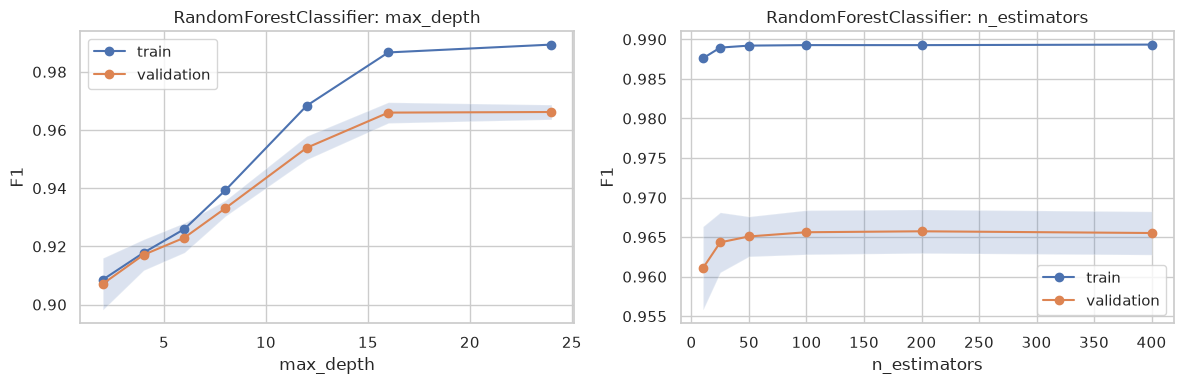

In [8]:
tree_best = tuned["RandomForest"].best_estimator_      # bagged trees: easy to read, two clear knobs
param_ranges = {"max_depth": [2, 4, 6, 8, 12, 16, 24], "n_estimators": [10, 25, 50, 100, 200, 400]}
fig, axes = plt.subplots(1, len(param_ranges), figsize=(6 * len(param_ranges), 4))
axes = np.atleast_1d(axes)
for ax, (p, vals) in zip(axes, param_ranges.items()):
    tr, va = validation_curve(tree_best, X_train, y_train, param_name=p, param_range=vals, cv=CV, scoring="f1", n_jobs=-1)
    ax.plot(vals, tr.mean(1), "o-", label="train"); ax.plot(vals, va.mean(1), "o-", label="validation")
    ax.fill_between(vals, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.2)
    ax.set_xlabel(p); ax.set_ylabel("F1"); ax.set_title(f"{type(tree_best).__name__}: {p}"); ax.legend()
plt.tight_layout(); plt.show()

> **Reading the output:** Train F1 stays above validation F1 and the gap grows with depth, which is the sign of memorising. Validation F1 flattens after moderate depth and tree count, so more trees or depth give no gain, only extra cost.

## 5. Over/under-fitting check
Train F1 (on data the model saw) vs CV F1 (on unseen folds).

In [9]:
rows = []
for name, rs in tuned.items():
    m = rs.best_estimator_
    rows.append({"model": name, "train_f1": f1_score(y_train, m.predict(X_train)), "cv_f1": rs.best_score_})
fit_check = pd.DataFrame(rows).set_index("model")
fit_check["gap"] = fit_check.train_f1 - fit_check.cv_f1
fit_check.sort_values("cv_f1", ascending=False).round(4)

,train_f1,cv_f1,gap
model,,,
HistGradientBoosting,0.9887,0.9687,0.0201
ExtraTrees,0.9883,0.9672,0.0211
RandomForest,0.9887,0.9655,0.0232
GradientBoosting,0.9808,0.9653,0.0155
LogisticRegression,0.9323,0.9303,0.0021


> **Reading the output:** Train F1 is about 0.99 vs CV 0.965-0.969 for the tree models, a gap of 0.02. That is mild overfitting, normal for ensembles. LogisticRegression has almost no gap (0.002) but also a low score, which is underfitting.

## 6. Ensemble: combine the best models
Soft voting averages predicted probabilities. Errors of different models often cancel.

In [10]:
top3 = tuning.index[:3].tolist()
voter = VotingClassifier([(n, tuned[n].best_estimator_) for n in top3], voting="soft")
r = cross_validate(voter, X_train, y_train, cv=CV, scoring=scoring, n_jobs=1)
ens_f1 = r["test_f1"].mean()
print("members:", top3)
print(f"ensemble CV F1 = {ens_f1:.4f} | best single = {tuning.tuned_f1.iloc[0]:.4f} ({tuning.index[0]})")
pd.Series({m: r[f"test_{m}"].mean() for m in scoring}).round(4)

members: ['HistGradientBoosting', 'ExtraTrees', 'RandomForest']
ensemble CV F1 = 0.9678 | best single = 0.9687 (HistGradientBoosting)


accuracy     0.9716
precision    0.9742
recall       0.9615
f1           0.9678
roc_auc      0.9968
dtype: float64

> **Reading the output:** Soft voting of the top 3 gives CV F1 0.9678, slightly below the best single model (0.9687). The members are all tree-based and make similar mistakes, so averaging adds nothing. The simpler single model wins.

## 7. Pick the winner and save
We keep every tuned model (plus the ensemble) so notebook 05 can compare them on the test set.

In [11]:
candidates = {n: rs.best_estimator_ for n, rs in tuned.items()}
voter.fit(X_train, y_train)
candidates["VotingEnsemble"] = voter

cv_scores = {n: rs.best_score_ for n, rs in tuned.items()} | {"VotingEnsemble": ens_f1}
best_name = max(cv_scores, key=cv_scores.get)
print("selected by CV F1:", best_name, round(cv_scores[best_name], 4))

joblib.dump(candidates[best_name], IN / "best_model.joblib")
joblib.dump(candidates, IN / "tuned_models.joblib")
pd.Series(cv_scores).to_json(IN / "cv_scores.json")
print("saved best_model.joblib, tuned_models.joblib, cv_scores.json")

selected by CV F1: HistGradientBoosting 0.9687


saved best_model.joblib, tuned_models.joblib, cv_scores.json


> **Reading the output:** HistGradientBoosting is selected by CV F1 (0.9687). All tuned models and the ensemble are saved so notebook 05 can compare them fairly on the untouched test set.

## Takeaways
- Tree ensembles beat linear and distance models by about 3 F1 points on this data.
- Tuning mattered for boosting (+0.8 to +2.6 points) and not for forests.
- Mild overfitting (gap about 0.02) is acceptable. More depth or trees did not help.
- Ensemble gave no benefit because the members are too similar. Winner by CV: `HistGradientBoosting`.